# Week 03 | AI Frontier: Review Clustering with Text Embeddings
**Marketing Strategy — Managing Customer Heterogeneity**

**Business question:** Can we discover recurring themes in customer reviews without defining survey attributes in advance?

In the Boats workshop, we represent customers using structured survey responses. Here, we represent unstructured review text using a pretrained neural network, then apply the familiar K-means algorithm.

**Workflow:** Raw reviews → Data exploration → Sentence embeddings → K-means → Interpretation.

### How to run
1. Open this `.ipynb` in [Google Colab](https://colab.research.google.com/) using **File → Upload notebook**, or in Jupyter.
2. Run the cells from top to bottom. Internet access is needed to install the package and download the public data and model the first time. No API key or paid inference service is required. A CPU is sufficient; a GPU is optional.
3. The notebook automatically reads the original CSV from GitHub, or uses a local `fine_food_reviews_1k.csv` if present. In Colab you can upload that file using the Files sidebar before running the loading cell.

Data: [Amazon Fine Food Reviews — 1,000-review teaching subset](https://github.com/openai/openai-cookbook/blob/main/examples/data/fine_food_reviews_1k.csv). The original [Cookbook clustering example](https://developers.openai.com/cookbook/examples/clustering) inspires this exercise, but we generate new embeddings locally with Sentence Transformers rather than using precomputed OpenAI vectors. This is review clustering, not customer-level segmentation.

In [ ]:
%pip install sentence-transformers

In [1]:
import html
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

SEED = 42
pd.set_option("display.max_colwidth", 220)

## 1. Data overview

Each row represents one review. Inspect the identifiers, rating, title, body and timestamp before deciding which variables to use.

In [2]:
DATA_URL = "https://raw.githubusercontent.com/openai/openai-cookbook/main/examples/data/fine_food_reviews_1k.csv"
LOCAL_FILE = Path("fine_food_reviews_1k.csv")

raw = pd.read_csv(LOCAL_FILE if LOCAL_FILE.exists() else DATA_URL)
# Remove the saved CSV row index, not a substantive variable.
raw = raw.loc[:, ~raw.columns.str.startswith("Unnamed:")].copy()
required = {"Time", "ProductId", "UserId", "Score", "Summary", "Text"}
assert required.issubset(raw.columns), f"Missing columns: {required - set(raw.columns)}"

print(f"Number of reviews: {len(raw):,}")
print(f"Number of original variables: {raw.shape[1]}")
display(raw.head())

Number of reviews: 1,000
Number of original variables: 6


,Time,ProductId,UserId,Score,Summary,Text
0,1351123200,B003XPF9BO,A3R7JR3FMEBXQB,5,where does one start...and stop... with a treat like this,Wanted to save some to bring to my Chicago family but my North Carolina family ate all 4 boxes before I could pack. These are excellent...could serve to anyone
1,1351123200,B003JK537S,A3JBPC3WFUT5ZP,1,Arrived in pieces,"Not pleased at all. When I opened the box, most of the rings were broken in pieces. A total waste of money."
2,1351123200,B000JMBE7M,AQX1N6A51QOKG,4,"It isn't blanc mange, but isn't bad . . .","I'm not sure that custard is really custard without eggs. But this comes close. I got it for use in a ""Vegan pancake"" recipe. We were having houseguests who were Vegan and I wanted to make some special breakfasts ..."
3,1351123200,B004AHGBX4,A2UY46X0OSNVUQ,3,These also have SALT and it's not sea salt.,"I like the fact that you can see what you're getting and that there are no bones or dark meat. There are 7 nice big chunks in every jar.<br /><br />These taste like tuna in a can but, because they're preserved in gl..."
4,1351123200,B001BORBHO,A1AFOYZ9HSM2CZ,5,Happy with the product,My dog was suffering with itchy skin. He had been eating Natural Choice brand (cheaper) since he was a puppy. I was nervous to change foods. The vet suggested to change foods sand see if the skin issues cleared up...


| Variable | Meaning | Role in this exercise |
|---|---|---|
| Time | Review timestamp (Unix seconds) | Overview |
| ProductId | Product identifier | Overview |
| UserId | Reviewer identifier | Overview |
| Score | Rating from 1 to 5 | Descriptive analysis and cluster profiling |
| Summary | Review title | Embedding input |
| Text | Review body | Embedding input |

Only the title and body are used to generate embeddings. Rating, product ID and reviewer ID are not features in the clustering model.

In [3]:
# Check variable types, missing values and duplicate rows.
overview = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "distinct_values": raw.nunique()
})
display(overview)
print("Exact duplicate rows:", raw.duplicated().sum())

,dtype,missing,distinct_values
Time,int64,0,2
ProductId,str,0,868
UserId,str,0,708
Score,int64,0,5
Summary,str,0,721
Text,str,0,761


Exact duplicate rows: 0


### Prepare the text

Remove HTML tags and extra whitespace, retain words and punctuation, and combine the title and review body. A missing title is allowed, but an empty review body is excluded. Ratings outside 1–5 are treated as missing for profiling only. Exact duplicate rows are reported above and retained in this demonstration to preserve the source sample.

In [4]:
def clean_text(value):
    if pd.isna(value):
        return ""
    text = html.unescape(str(value))
    text = re.sub(r"<[^>]+>", " ", text)
    return re.sub(r"\s+", " ", text).strip()

df = raw.copy()
df["clean_title"] = df["Summary"].map(clean_text)
df["clean_body"] = df["Text"].map(clean_text)
df = df.loc[df["clean_body"].ne("")].reset_index(drop=True)
df["review_text"] = (
    df["clean_title"].where(df["clean_title"].eq(""), df["clean_title"] + ". ")
    + df["clean_body"]
).str.strip()

df["Score"] = pd.to_numeric(df["Score"], errors="coerce")
df.loc[~df["Score"].isin([1, 2, 3, 4, 5]), "Score"] = np.nan
df["review_date"] = pd.to_datetime(df["Time"], unit="s", errors="coerce", utc=True)
df["word_count"] = df["clean_body"].str.split().str.len()

print(f"Reviews retained: {len(df):,} of {len(raw):,}")
display(df[["Summary", "review_text", "Score"]].head(3))

Reviews retained: 1,000 of 1,000


,Summary,review_text,Score
0,where does one start...and stop... with a treat like this,where does one start...and stop... with a treat like this. Wanted to save some to bring to my Chicago family but my North Carolina family ate all 4 boxes before I could pack. These are excellent...could serve to anyone,5.0
1,Arrived in pieces,"Arrived in pieces. Not pleased at all. When I opened the box, most of the rings were broken in pieces. A total waste of money.",1.0
2,"It isn't blanc mange, but isn't bad . . .","It isn't blanc mange, but isn't bad . . .. I'm not sure that custard is really custard without eggs. But this comes close. I got it for use in a ""Vegan pancake"" recipe. We were having houseguests who were Vegan and I...",4.0


## 2. Basic descriptive analysis

Before using AI, understand the sample: how many products and reviewers are represented, how positive the reviews are, and how long the review texts are. The teaching subset is not necessarily representative of the full Amazon review population.

In [5]:
summary = pd.Series({
    "Reviews": len(df),
    "Unique reviewers": df["UserId"].nunique(),
    "Unique products": df["ProductId"].nunique(),
    "Mean star rating": df["Score"].mean(),
    "Median star rating": df["Score"].median(),
    "Mean review length (words)": df["word_count"].mean(),
    "Median review length (words)": df["word_count"].median()
}, name="Value")
display(summary.round(2).to_frame())
print("Review date range:", df["review_date"].min(), "to", df["review_date"].max())
display(df[["Score", "word_count"]].describe().round(2))

,Value
Reviews,1000.00
Unique reviewers,708.00
Unique products,868.00
Mean star rating,4.22
Median star rating,5.00
Mean review length (words),67.71
Median review length (words),50.00


Review date range: 2012-10-25 00:00:00+00:00 to 2012-10-26 00:00:00+00:00


,Score,word_count
count,1000.00,1000.00
mean,4.22,67.71
std,1.29,56.95
min,1.00,20.00
25%,4.00,30.00
50%,5.00,50.00
75%,5.00,85.00
max,5.00,517.00


,Reviews,Percent of valid ratings
Score,,
1,87,8.7
2,49,4.9
3,75,7.5
4,138,13.8
5,651,65.1


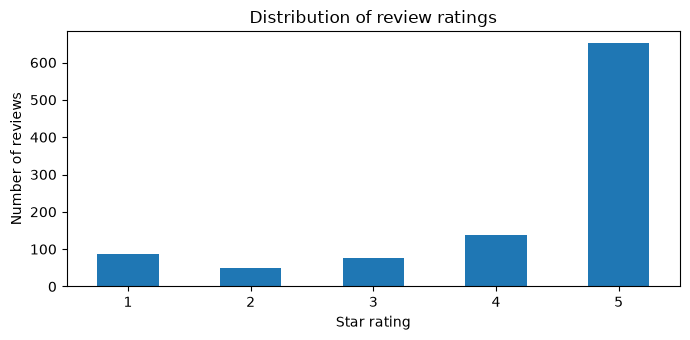

In [6]:
# Star-rating distribution
ratings = df["Score"].value_counts().reindex(range(1, 6), fill_value=0)
rating_table = pd.DataFrame({"Reviews": ratings, "Percent of valid ratings": 100 * ratings / ratings.sum()})
display(rating_table.round(1))

ax = ratings.plot.bar(rot=0, figsize=(7, 3.5))
ax.set(xlabel="Star rating", ylabel="Number of reviews", title="Distribution of review ratings")
plt.tight_layout()
plt.show()

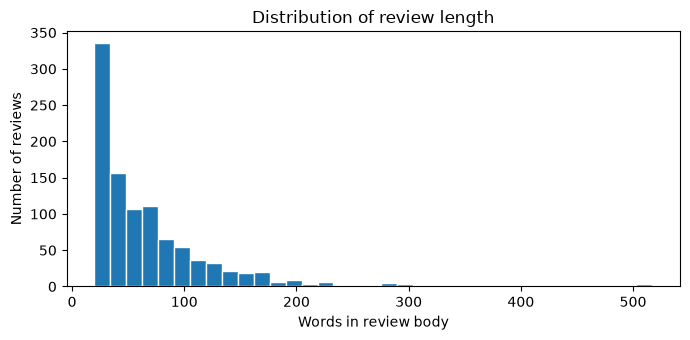

In [7]:
# Review length distribution
plt.figure(figsize=(7, 3.5))
plt.hist(df["word_count"], bins=35, edgecolor="white")
plt.xlabel("Words in review body")
plt.ylabel("Number of reviews")
plt.title("Distribution of review length")
plt.tight_layout()
plt.show()

**Class discussion:** Are most reviews positive or negative? Do all reviews contain the same amount of information? Could ratings alone tell us why customers liked or disliked a product?

## 3. Generate text embeddings

A pretrained Sentence Transformer maps a text into a fixed-length numerical vector. We use [`all-MiniLM-L6-v2`](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2), which produces 384-dimensional embeddings for English text. We do not train or fine-tune the model.

We first illustrate semantic similarity, then encode the entire review dataset. Normalizing vectors to unit length makes their dot product equal to cosine similarity and puts the reviews on a common scale before clustering.

**Model limitation:** This model normally processes at most 256 subword tokens per text; longer combined reviews are truncated by default. Word counts above are not token counts. For this introductory demonstration we accept truncation; a production project could split long reviews into chunks and aggregate their embeddings.

In [8]:
from sentence_transformers import SentenceTransformer
import torch

MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"
device = "cuda" if torch.cuda.is_available() else "cpu"
model = SentenceTransformer(MODEL_NAME, device=device)
print("Device:", device)
print("Embedding dimension:", model.get_sentence_embedding_dimension())
print("Maximum input length (tokens):", model.max_seq_length)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

C:\Users\N2606370H\AppData\Local\Programs\Python\Python314\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\N2606370H\.cache\huggingface\hub\models--sentence-transformers--all-MiniLM-L6-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (7 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Device: cpu
Embedding dimension: 384
Maximum input length (tokens): 256


C:\Users\N2606370H\AppData\Local\Temp\ipykernel_25672\3237775719.py:8: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  print("Embedding dimension:", model.get_sentence_embedding_dimension())


### 3.1 A small semantic similarity demonstration

The following three sentences are illustrative examples, not quotes from the dataset. Compare a pair with similar meaning to an unrelated sentence. Larger cosine similarity means the vectors point in more similar directions; it does not guarantee identical meaning.

In [9]:
examples = [
    "The coffee tastes wonderful.",
    "I really enjoyed the flavor of this coffee.",
    "My dog loves these treats."
]
example_vectors = model.encode(examples, normalize_embeddings=True, convert_to_numpy=True)
similarity = example_vectors @ example_vectors.T
for i, text in enumerate(examples, start=1):
    print(f"Sentence {i}: {text}")
labels = [f"Sentence {i}" for i in range(1, len(examples) + 1)]
display(pd.DataFrame(similarity, index=labels, columns=labels).round(3))

Sentence 1: The coffee tastes wonderful.
Sentence 2: I really enjoyed the flavor of this coffee.
Sentence 3: My dog loves these treats.


,Sentence 1,Sentence 2,Sentence 3
Sentence 1,1.000,0.774,0.230
Sentence 2,0.774,1.000,0.292
Sentence 3,0.230,0.292,1.000


### 3.2 Encode all reviews

One review becomes one vector. For the full 1,000-row dataset with no empty review bodies, the expected matrix shape is `(1000, 384)`. This step performs model inference on the original text, not a lookup of precomputed vectors.

In [10]:
embeddings = model.encode(
    df["review_text"].tolist(),
    batch_size=32,
    normalize_embeddings=True,
    convert_to_numpy=True,
    show_progress_bar=True
)
assert embeddings.shape == (len(df), 384)
assert np.isfinite(embeddings).all()
print("Embedding matrix shape:", embeddings.shape)
print("First review:", df.loc[0, "review_text"][:250])
print("First 10 coordinates:", np.round(embeddings[0, :10], 4))
print("Vector norm:", round(float(np.linalg.norm(embeddings[0])), 4))

Batches:   0%|          | 0/32 [00:00<?, ?it/s]

Embedding matrix shape: (1000, 384)
First review: where does one start...and stop... with a treat like this. Wanted to save some to bring to my Chicago family but my North Carolina family ate all 4 boxes before I could pack. These are excellent...could serve to anyone
First 10 coordinates: [ 0.0581  0.0212  0.0235  0.0538 -0.0442  0.0026 -0.0159 -0.0817 -0.0571
 -0.0357]
Vector norm: 1.0


The embedding matrix has one row per review and 384 columns. Individual coordinates generally do not have a human-readable label (unlike the interpreted components in the Boats PCA exercise). The semantic information is distributed across the vector.

### 3.3 Find similar real reviews (optional demonstration)

Use cosine similarity to retrieve the nearest reviews to a selected review. Change `review_idx` to explore a different example. No ratings or product labels enter the similarity calculation.

In [11]:
review_idx = 0
similarities = embeddings @ embeddings[review_idx]
similarities[review_idx] = -np.inf  # Exclude the query itself.
nearest = np.argsort(similarities)[::-1][:3]

print("QUERY:", df.loc[review_idx, "review_text"][:400])
print("\nMOST SIMILAR REVIEWS:")
for i in nearest:
    print(f"\nCosine similarity: {similarities[i]:.3f}")
    print(df.loc[i, "review_text"][:400])

QUERY: where does one start...and stop... with a treat like this. Wanted to save some to bring to my Chicago family but my North Carolina family ate all 4 boxes before I could pack. These are excellent...could serve to anyone

MOST SIMILAR REVIEWS:

Cosine similarity: 0.515
Delicious!. Love these packs. I have made pretzel dogs, bites and sticks. I have even used the pretzel mix to make calzones and pizza. Both came out great.

Cosine similarity: 0.488
Awesome. They arrived before the expected time and were of fantastic quality. Would recommend to any one looking for a awesome treat

Cosine similarity: 0.481
Tasty!. I purchased this to send to my son who's away at college. It was delivered right to his dorm room with very fast shipping. He loved it so much he called me to thank me, and sadly, he hardly ever calls me anymore! If you want your kids to call home, and have some good snack to get them through midterms then send them this.


## 4. Cluster analysis

K-means groups the normalized embedding vectors by minimizing within-cluster squared Euclidean distances. It does not use review ratings, product IDs, or manually supplied theme labels.

### 4.1 Fit K-means

Start with four clusters, following the teaching example in the Cookbook. Four is an illustrative choice, not an empirically established optimal number. Since the embedding model differs from the original example, the resulting clusters may also differ.

In [12]:
K = 4
kmeans = KMeans(n_clusters=K, random_state=SEED, n_init=10)
df["Cluster"] = kmeans.fit_predict(embeddings) + 1  # Labels 1, ..., K

cluster_counts = df["Cluster"].value_counts().sort_index()
display(pd.DataFrame({"Reviews": cluster_counts, "Share (%)": 100 * cluster_counts / len(df)}).round(1))
print(f"Silhouette score (Euclidean, full embeddings): {silhouette_score(embeddings, df['Cluster']):.3f}")

,Reviews,Share (%)
Cluster,,
1,138,13.8
2,180,18.0
3,453,45.3
4,229,22.9


Silhouette score (Euclidean, full embeddings): 0.053


### 4.2 Visualize the clusters in two dimensions

The actual clustering uses all 384 embedding dimensions. PCA is applied **after clustering**, only to make a 2D scatter plot. Nearby points in this plot give an approximate view of similarity; overlap does not automatically imply that the original high-dimensional clusters are poor.

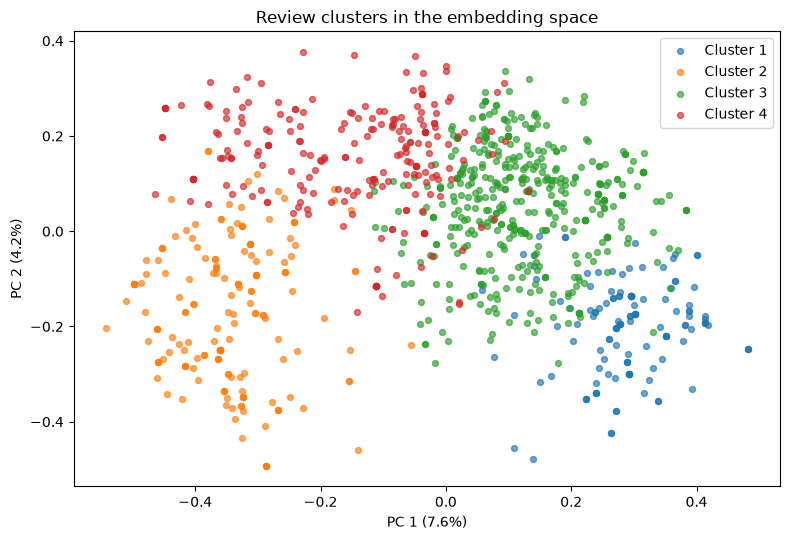

Variance captured by the 2D projection: 11.8%


In [13]:
pca = PCA(n_components=2, random_state=SEED)
coords = pca.fit_transform(embeddings)

fig, ax = plt.subplots(figsize=(8, 5.5))
for cluster in sorted(df["Cluster"].unique()):
    mask = df["Cluster"].eq(cluster).to_numpy()
    ax.scatter(coords[mask, 0], coords[mask, 1], s=18, alpha=0.65, label=f"Cluster {cluster}")
ax.set(xlabel=f"PC 1 ({pca.explained_variance_ratio_[0]:.1%})",
       ylabel=f"PC 2 ({pca.explained_variance_ratio_[1]:.1%})",
       title="Review clusters in the embedding space")
ax.legend()
plt.tight_layout()
plt.show()
print(f"Variance captured by the 2D projection: {pca.explained_variance_ratio_.sum():.1%}")

### 4.3 Profile the clusters

Now bring the ratings back into the analysis as external descriptive variables. Which themes appear most frequently? Are some associated with lower ratings?

,reviews,share_pct,valid_ratings,mean_rating,median_rating,mean_words,distinct_products
Cluster,,,,,,,
1,138,13.8,138,4.18,5.0,87.33,131
2,180,18.0,180,4.16,5.0,59.24,140
3,453,45.3,453,4.15,5.0,68.01,419
4,229,22.9,229,4.42,5.0,61.94,207


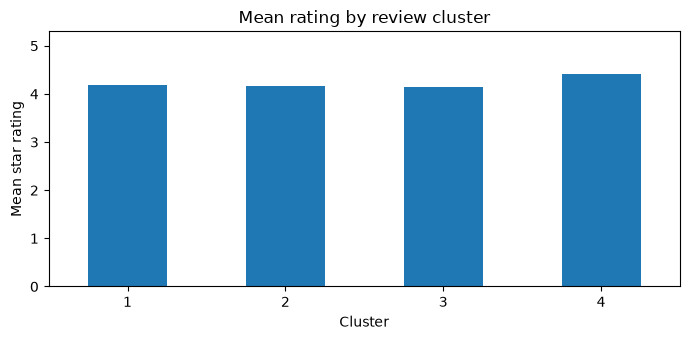

In [14]:
profiles = df.groupby("Cluster").agg(
    reviews=("review_text", "size"),
    valid_ratings=("Score", "count"),
    mean_rating=("Score", "mean"),
    median_rating=("Score", "median"),
    mean_words=("word_count", "mean"),
    distinct_products=("ProductId", "nunique")
)
profiles["share_pct"] = 100 * profiles["reviews"] / len(df)
profiles = profiles[["reviews", "share_pct", "valid_ratings", "mean_rating", "median_rating", "mean_words", "distinct_products"]]
display(profiles.round(2))

ax = profiles["mean_rating"].plot.bar(figsize=(7, 3.5), rot=0)
ax.set(xlabel="Cluster", ylabel="Mean star rating", title="Mean rating by review cluster", ylim=(0, 5.3))
plt.tight_layout()
plt.show()

### 4.4 Interpret and name the clusters

K-means returns cluster numbers, not meanings. Inspect reviews closest to each centroid in the original embedding space to identify recurring themes. Then inspect a random review as a check against overinterpreting the most central texts. Cluster numbers have no natural ordering.

In [15]:
# Show five central reviews per cluster, plus one randomly selected review.
for cluster in range(1, K + 1):
    group_idx = np.flatnonzero(df["Cluster"].to_numpy() == cluster)
    if not len(group_idx):
        continue
    center = kmeans.cluster_centers_[cluster - 1]
    distances = np.linalg.norm(embeddings[group_idx] - center, axis=1)
    central_idx = group_idx[np.argsort(distances)[:5]]
    print(f"\n{'=' * 65}\nCLUSTER {cluster} | {len(group_idx)} reviews\n{'=' * 65}")
    for i in central_idx:
        print(f"\nRating: {df.loc[i, 'Score']} | {df.loc[i, 'clean_title']}")
        print(df.loc[i, "clean_body"][:500])
    random_idx = df.loc[group_idx].sample(1, random_state=SEED).index[0]
    print("\nRandom review (sanity check):")
    print(df.loc[random_idx, "review_text"][:500])


CLUSTER 1 | 138 reviews

Rating: 1.0 | terrible treats
My dogs love them but they are loaded with junk and come from another country. these went in the trash once i read that. I buy USA only and not loaded with junk like caramel coloring or anything thats a preservative. stay away from these. not good for your dogs.

Rating: 5.0 | Paws up!
We try different treats for our dogs and they seem to like the Holistic Select biscuits very much. This has good quality ingredients just like their kibbles which our dogs like as well.

Rating: 5.0 | Paws up!
We try different treats for our dogs and they seem to like the Holistic Select biscuits very much. This has good quality ingredients just like their kibbles which our dogs like as well.

Rating: 3.0 | Dog Loves it . . . While it Lasts
I bought this flavor edible Nylabone for my "industrial strength" chewing dog who's just over 1 year old. Although he enjoys all of the Nylabone flavors, he goes through them in record time because he's a chronic

**Class exercise:** Give each cluster a short name based on the observed reviews, not a name assumed in advance. Explain the main theme, whether it is about a product category, a customer need, or a service issue, and one marketing action that could be informed by it.

In [16]:
# Replace these placeholder labels after inspecting the representative reviews.
cluster_names = {c: f"Cluster {c} (name to be assigned)" for c in range(1, K + 1)}
# Example syntax: cluster_names[1] = "Your observed theme"
df["ClusterName"] = df["Cluster"].map(cluster_names)
result = profiles.copy()
result.insert(0, "Theme", [cluster_names[c] for c in result.index])
display(result.round(2))

,Theme,reviews,share_pct,valid_ratings,mean_rating,median_rating,mean_words,distinct_products
Cluster,,,,,,,,
1,Cluster 1 (name to be assigned),138,13.8,138,4.18,5.0,87.33,131
2,Cluster 2 (name to be assigned),180,18.0,180,4.16,5.0,59.24,140
3,Cluster 3 (name to be assigned),453,45.3,453,4.15,5.0,68.01,419
4,Cluster 4 (name to be assigned),229,22.9,229,4.42,5.0,61.94,207


### 4.5 Optional: Does the number of clusters matter?

Compare K = 2 to 8 using inertia (within-cluster sum of squared distances) and silhouette score (separation versus cohesion, using Euclidean distance in the full embedding space). Inertia normally decreases with more clusters; a larger silhouette is usually preferable, but neither statistic decides whether a solution is useful for marketing. Inspect themes and cluster sizes as well. This cell does not overwrite the four-cluster solution above.

,Inertia,Silhouette
K,,
2,702.265,0.053
3,677.394,0.057
4,661.119,0.053
5,646.152,0.053
6,635.094,0.056
7,626.212,0.057
8,621.606,0.048


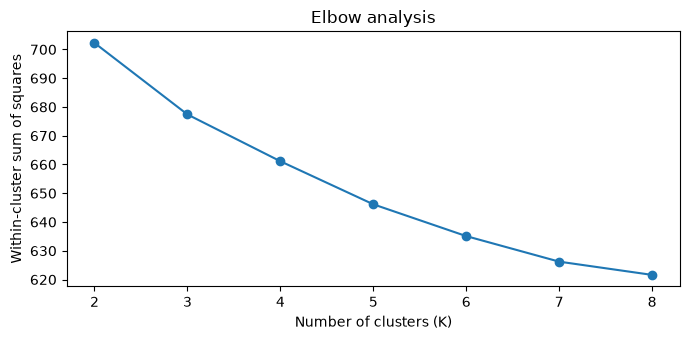

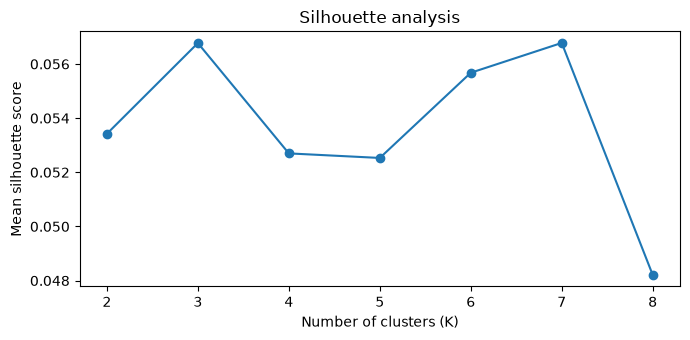

In [17]:
comparison = []
for k in range(2, min(8, len(df) - 1) + 1):
    alternative = KMeans(n_clusters=k, random_state=SEED, n_init=10)
    labels_k = alternative.fit_predict(embeddings)
    comparison.append({"K": k, "Inertia": alternative.inertia_,
                       "Silhouette": silhouette_score(embeddings, labels_k)})
comparison = pd.DataFrame(comparison).set_index("K")
display(comparison.round(3))

ax = comparison["Inertia"].plot(marker="o", figsize=(7, 3.5), xticks=comparison.index)
ax.set(xlabel="Number of clusters (K)", ylabel="Within-cluster sum of squares", title="Elbow analysis")
plt.tight_layout()
plt.show()

ax = comparison["Silhouette"].plot(marker="o", figsize=(7, 3.5), xticks=comparison.index)
ax.set(xlabel="Number of clusters (K)", ylabel="Mean silhouette score", title="Silhouette analysis")
plt.tight_layout()
plt.show()

### 4.6 Optional: Export the review-level results

Save the assigned clusters for further analysis in Excel or Python. The output CSV does not contain the high-dimensional vectors; these are saved separately in a NumPy file, with rows in the same order as the CSV.

In [18]:
output_columns = ["Time", "ProductId", "UserId", "Score", "Summary", "Text", "Cluster", "ClusterName"]
df[output_columns].to_csv("amazon_review_clusters.csv", index=False)
np.save("amazon_review_embeddings.npy", embeddings)
print("Saved amazon_review_clusters.csv and amazon_review_embeddings.npy")

Saved amazon_review_clusters.csv and amazon_review_embeddings.npy


## Takeaways for marketing strategy

- **Representation is the AI frontier:** The clustering algorithm is still K-means, but a pretrained model can transform unstructured feedback into machine-readable features without a fixed survey questionnaire.
- **Interpretation remains managerial:** The algorithm may separate product categories, sentiment, product features or customer concerns. Read the reviews and validate the themes before making decisions.
- **Unit of analysis matters:** One review is not necessarily one unique customer. A review cluster should not automatically be described as a customer segment.
- **Validation matters:** The sample is small and dated, the model truncates long reviews, and a cluster's mean rating is descriptive rather than evidence of causation. Test stability across samples, models and choices of K before deployment.

### References
- [Original Amazon Fine Food Reviews dataset](https://www.kaggle.com/datasets/snap/amazon-fine-food-reviews)
- [OpenAI Cookbook: Raw 1,000-review sample](https://github.com/openai/openai-cookbook/blob/main/examples/data/fine_food_reviews_1k.csv)
- [OpenAI Cookbook: Clustering](https://developers.openai.com/cookbook/examples/clustering)
- [Sentence Transformers model card](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2)
- [Scikit-learn K-means](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html)